# **Task 2: New model on the same data.**

This notebook compares a validation-tuned **Lasso** model with the Task 1 **Ridge** benchmark. Each Monte Carlo run is regenerated through the same shared DGP-and-permutation function using the same seed as Task 1. 

Lasso's regularization is selected using only an internal training/validation split; the test sample is reserved for final OOS metrics.

In [35]:
import csv
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# Support execution with either the project root or notebooks/ as the working directory.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.config
import src.dgp
import src.models
import src.metrics
importlib.reload(src.config)
importlib.reload(src.dgp)
importlib.reload(src.models)
importlib.reload(src.metrics)
import src
importlib.reload(src)
import src.plotting as plot
importlib.reload(plot)

from src import (
    DGP_DEFAULTS,
    CQ_GRID,
    N_RUNS,
    SEED,
    FIG_DIR,
    RESULT_DIR,
    LASSO_ALPHA_FRACTIONS,
    generate_dgp_run,
    get_observed_block,
    fit_lasso_with_validation,
    eval_oos_performance, 
)

FIG_PATH = PROJECT_ROOT / FIG_DIR
RESULT_PATH = PROJECT_ROOT / RESULT_DIR
FIG_PATH.mkdir(parents=True, exist_ok=True)
RESULT_PATH.mkdir(parents=True, exist_ok=True)

T_tr = DGP_DEFAULTS["T_train"]
P_total = int(DGP_DEFAULTS["c"] * T_tr)
METRICS = ["r2_paper", "exp_return", "sharpe", "beta_norm_sq"]

## I. Model and tuning protocol

For each observed feature block, split the training observations chronologically: the first 80% fit candidate models and the final 20% select the penalty by validation MSE. Since the simulated observations are i.i.d., this fixed split preserves the training-only tuning rule. Lasso uses no intercept, matching the zero-mean DGP and Task 1's no-intercept convention. The alpha grid is scaled using only the fitting block; after selection, the same absolute alpha is refit on all training rows. The reported selected-alpha validation MSE is the tuning criterion for the candidate path, not a test metric or a new error estimate for the refit model. The test sample remains reserved for final OOS metrics.

With T_train=500, the holdout contains 100 observations. At cq=10, the model has 5,000 observed features, so the single-holdout alpha choice can have substantial sampling noise. This is a limitation of the tuning estimate, not test leakage; interpret selected penalties accordingly.

## II. Matched Monte Carlo evaluation

The run index, DGP parameters, and feature permutation follow Task 1 exactly through `generate_dgp_run`. For each `cq`, the Lasso model sees the same first `P1` permuted features. We record the four requested OOS metrics: paper $R^2$, expected timing return, the paper's Sharpe ratio, and squared parameter norm.

In [24]:
n_runs = N_RUNS
results = {metric: np.full((n_runs, len(CQ_GRID)), np.nan) for metric in METRICS}
selected_alphas = np.full((n_runs, len(CQ_GRID)), np.nan)
selected_alpha_validation_mses = np.full((n_runs, len(CQ_GRID)), np.nan)

print("Running matched Monte Carlo simulations for Task 2...\n")
for run in tqdm(range(n_runs)):
    S_tr, R_tr, S_te, R_te, beta_star, P, permuted_indices = generate_dgp_run(
        **DGP_DEFAULTS,
        seed=SEED + run,
    )
    if P != P_total:
        raise RuntimeError(f"Unexpected feature count for run {run}: {P} != {P_total}")

    for i, cq in enumerate(CQ_GRID):
        P1 = int(round(cq * T_tr))
        X_tr, X_te = get_observed_block(S_tr, S_te, P1, permuted_indices)
        beta_hat, alpha, selected_alpha_validation_mse = fit_lasso_with_validation(X_tr, R_tr)
        performance = eval_oos_performance(beta_hat, X_te, R_te)

        for metric in METRICS:
            results[metric][run, i] = performance[metric]
        selected_alphas[run, i] = alpha
        selected_alpha_validation_mses[run, i] = selected_alpha_validation_mse

avg_results = {metric: np.mean(values, axis=0) for metric, values in results.items()}
std_results = {metric: np.std(values, axis=0, ddof=1) for metric, values in results.items()}

lasso_metrics_path = RESULT_PATH / "task2_lasso_metrics.npz"
np.savez(
    lasso_metrics_path,
    cq_grid=np.asarray(CQ_GRID),
    alpha_fractions=LASSO_ALPHA_FRACTIONS,
    selected_alphas=selected_alphas,
    selected_alpha_validation_mses=selected_alpha_validation_mses,
    **results,
)

summary_columns = ["cq", "selected_alpha_mean", "selected_alpha_std", "selected_alpha_validation_mse_mean"]
summary_columns.extend(
    f"{metric}_{stat}"
    for metric in METRICS
    for stat in ("mean", "std")
)
summary_path = RESULT_PATH / "task2_lasso_summary.csv"
with summary_path.open("w", newline="", encoding="utf-8") as summary_file:
    writer = csv.writer(summary_file)
    writer.writerow(summary_columns)
    for i, cq in enumerate(CQ_GRID):
        row = [
            cq,
            np.mean(selected_alphas[:, i]),
            np.std(selected_alphas[:, i], ddof=1),
            np.mean(selected_alpha_validation_mses[:, i]),
        ]
        for metric in METRICS:
            row.extend([avg_results[metric][i], std_results[metric][i]])
        writer.writerow(row)

print(f"\nTask 2 finished. Metrics saved to {lasso_metrics_path}")
print(summary_path.read_text(encoding="utf-8"))

Running matched Monte Carlo simulations for Task 2...



100%|██████████| 20/20 [02:33<00:00,  7.67s/it]


Task 2 finished. Metrics saved to d:\Desktop\5205-project1\results\task2_lasso_metrics.npz
cq,selected_alpha_mean,selected_alpha_std,selected_alpha_validation_mse_mean,r2_paper_mean,r2_paper_std,exp_return_mean,exp_return_std,sharpe_mean,sharpe_std,beta_norm_sq_mean,beta_norm_sq_std
0.5,0.16306036388081907,0.0503495659112232,1.9865408337960677,-0.003731303978327399,0.006479740381762305,0.0028978405562767166,0.0039354540436757545,0.013819421640217117,0.018304237923494046,0.013173869018849187,0.019138219471852257
0.75,0.18678942806371576,0.05230095467583366,1.9834650712293183,-0.0037821882303491596,0.007849779328778991,0.0022504957127637173,0.0037081666659445236,0.009465192808609394,0.019480661838037244,0.012270115334772767,0.022280719869586046
0.9,0.18516063997604632,0.05373606988379639,1.9801474845444935,-0.005004361096613563,0.009037766827473488,0.0020008081195144528,0.003776872447749787,0.004261638613571995,0.016199406733035736,0.014094994831358407,0.024182350095487075
0.95,0.185160

## III. Compare with the Task 1 Ridge curves

The Lasso curve is the Monte Carlo mean after selecting alpha by the internal validation block separately for each run and `cq`; it is not selected using test performance. The Ridge traces are representative fixed-`z` Monte Carlo means from Task 1. This overlay compares the validation-tuned Lasso against Ridge reference curves, not a tuned-versus-tuned model-selection result; a strict selection comparison would tune Ridge on the same internal split as well.

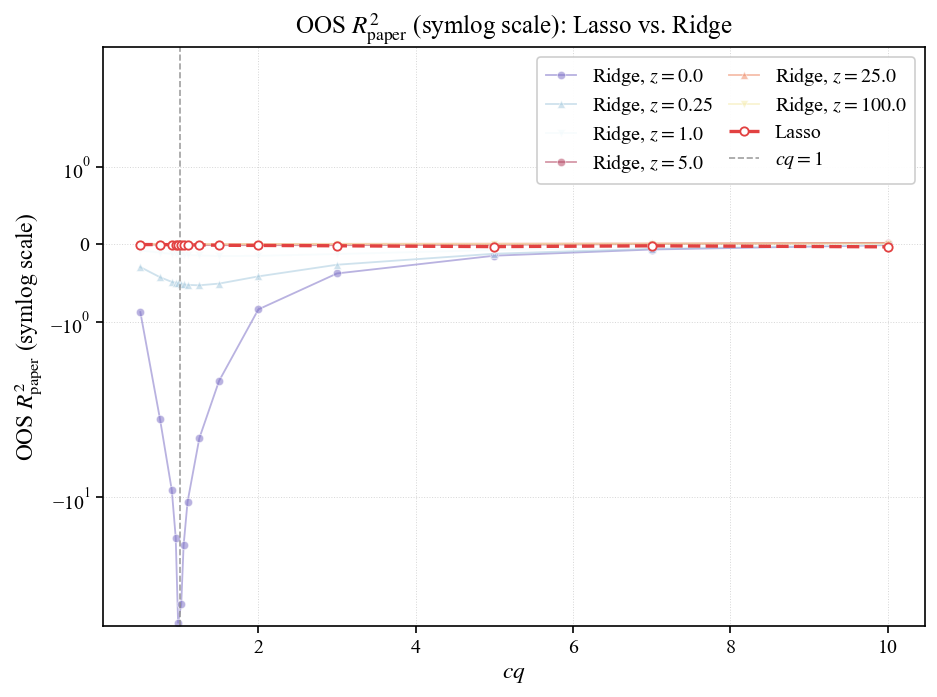

In [25]:
ridge_metrics_path = RESULT_PATH / "task1_ridge_metrics.npz"
if not ridge_metrics_path.exists():
    raise FileNotFoundError(
        f"Missing {ridge_metrics_path}. Run the Task 1 notebook first to create the Ridge benchmark."
    )

with np.load(ridge_metrics_path) as ridge_data:
    ridge_cq_grid = ridge_data["cq_grid"]
    ridge_z_grid = ridge_data["z_grid"]
    if not np.array_equal(ridge_cq_grid, np.asarray(CQ_GRID)):
        raise ValueError("Task 1 and Task 2 CQ_GRID values do not match")
    ridge_results = {metric: ridge_data[metric] for metric in METRICS}

metric_labels = {
    "r2_paper": (r"OOS $R^2_{\mathrm{paper}}$ (symlog scale)", r"OOS $R^2_{\mathrm{paper}}$ (symlog scale)", "symlog"),
    "exp_return": ("Expected Timing Return", r"$\mathbb{E}[R^{\pi}]$", None),
    "sharpe": ("Sharpe Ratio", "Sharpe Ratio", None),
    "beta_norm_sq": ("Parameter Norm", r"$\|\hat{\beta}\|_2^2$ (log scale)", "log"),
}
ridge_z_indices = [0, 2, 4, 6, 8, 10]
lasso_color = "#E24141"


def plot_lasso_ridge_metric(metric):
    metric_title, ylabel, yscale = metric_labels[metric]
    fig, ax = plt.subplots(figsize=plot.FIGSIZE)
    plot.plot_metric_grid(
        ax,
        ridge_cq_grid,
        ridge_results,
        ridge_z_grid,
        metric,
        plot_z_indices=ridge_z_indices,
    )
    for line in ax.lines:
        line.set_alpha(0.55)
        line.set_linewidth(1.1)
        line.set_label(f"Ridge, {line.get_label()}")
    ax.plot(
        CQ_GRID,
        avg_results[metric],
        color=lasso_color,
        marker="o",
        markersize=5,
        markerfacecolor="white",
        markeredgecolor=lasso_color,
        markeredgewidth=1.1,
        linestyle="--",
        linewidth=2.0,
        label="Lasso",
        zorder=5,
    )
    plot.add_interpolation_marker(ax)
    plot.finalize_and_save(
        fig,
        ax,
        title=f"{metric_title}: Lasso vs. Ridge",
        xlabel=r"$cq$",
        ylabel=ylabel,
        yscale=yscale,
        savepath=FIG_PATH / f"task2_lasso_vs_ridge_{metric}.{plot.FIG_FORMAT}",
        loc="best",
        ncol=2,
    )
    plt.show()


plot_lasso_ridge_metric("r2_paper")

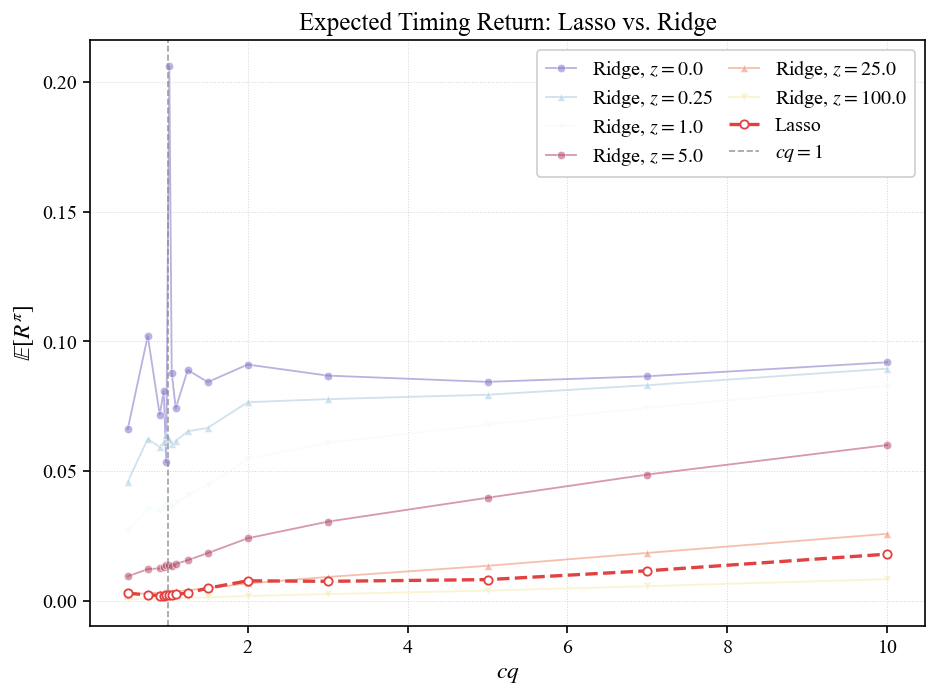

In [26]:
plot_lasso_ridge_metric("exp_return")

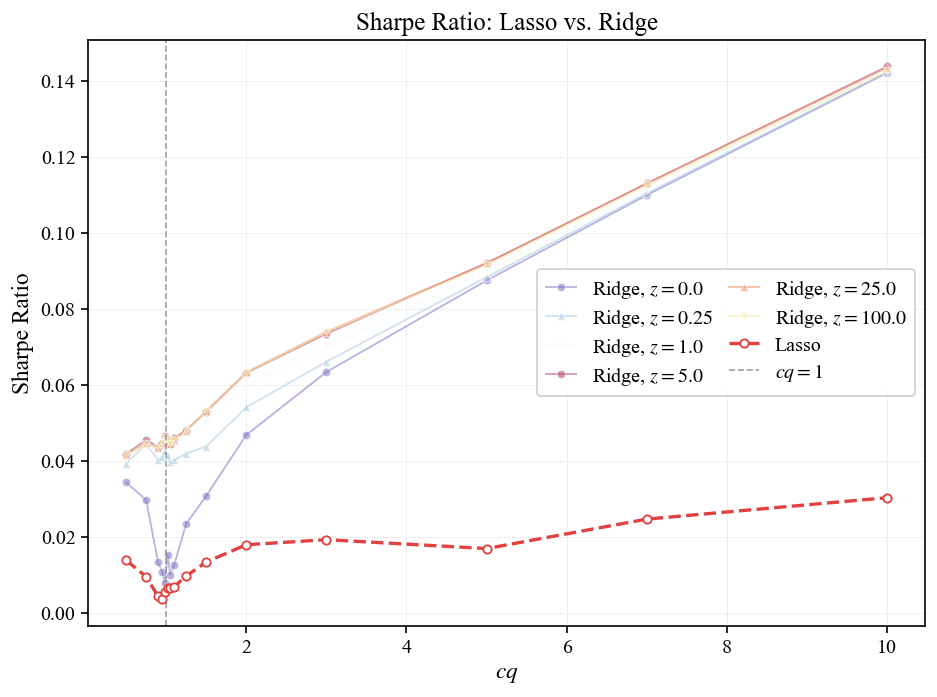

In [27]:
plot_lasso_ridge_metric("sharpe")

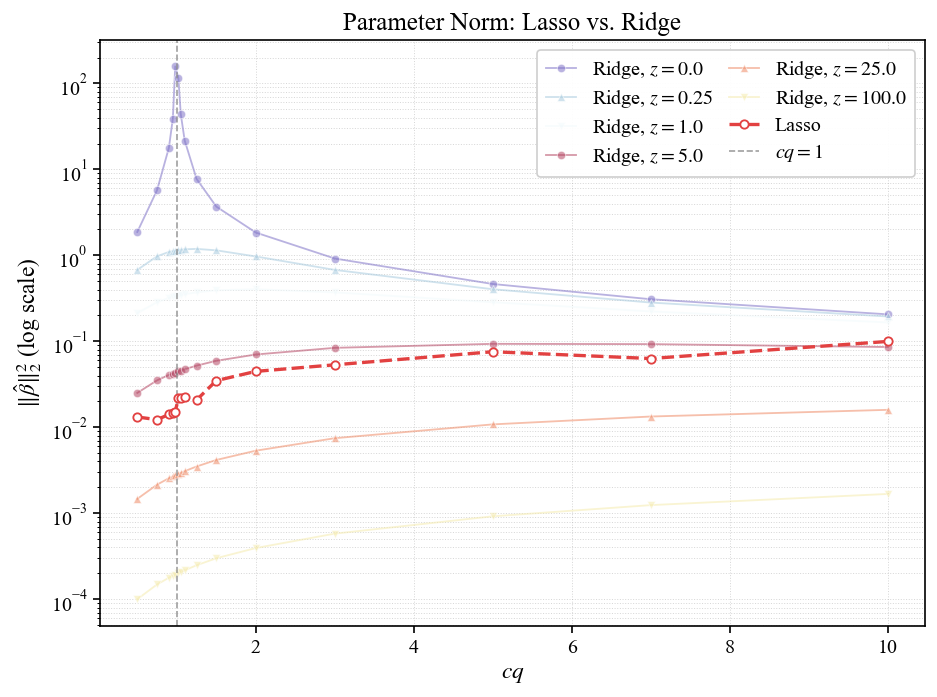

In [28]:
plot_lasso_ridge_metric("beta_norm_sq")

## IV. Discussion guide

The simulated true coefficient vector is dense, while Lasso favors sparse solutions. Interpret any difference from Ridge using the OOS metrics together with the selected penalty and parameter norm: stronger shrinkage may stabilize estimates near interpolation, but sparsity can also omit many weak signals and add bias. The DGP is linear, so differences here should not be attributed to nonlinear modeling. Base conclusions on the completed Monte Carlo curves rather than assuming Lasso must outperform Ridge.